Main question: Which kinds of energy projects make it from the interconnection queue to being built, and how long does it take?

- What % of projects get built/withdrawan, broken down by type

- How long do projects wait in queue before they start running, is it getting longer?

- How do NC/Southeast compare to rest of country?

- So what?


Data: Berkeley Lab, Queued Up 2026 Edition (projects thru 2025)

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
path = "/content/drive/MyDrive/Grid Line/LBNL_Ix_Queue_Data_File_thru2025.xlsx"
xl = pd.ExcelFile(path)
xl.sheet_names

['Introduction',
 'Contents',
 '00. Background + Methods',
 '01. Balancing Areas',
 '02. Data Sample by Region',
 '03. Complete Queue Data',
 '04. Data Codebook',
 '05. Annual Requests',
 '06. Capacity Change YoY',
 '07. Active Capacity by Year',
 '08. Active Capacity by Type',
 '09. Active Cap. Region+Type',
 '10. Queues vs. Installed',
 '11. Active Cap. Maps',
 '12. Ix. Request Size Trends',
 '13. Other Gen. + Storage',
 '14. Hybrid Capacity',
 '15. ERIS + NRIS Capacity',
 '16. Cap. by Prop. Online Year',
 '17. Cap. by Ix. Phase',
 '18. IA Executed Capacity',
 '19. IA Throughput by Region',
 '20. ERAS and RRI Requests',
 '21. Operational Volume Trend',
 '22. Withdrawn Volume Trend',
 '23. Completion Rate Trend',
 '24. Comp. Rate Gen Type',
 '25. Comp. Rate Region',
 '26. Withdrawn Ix. Phase',
 '27. Post-IA Completion',
 '28. IR to WD',
 '29. IR to IA - all',
 '30. IR to IA - region',
 '31. IR to IA - type',
 '32. IR to IA - size',
 '33. IR to IA - service',
 '34. IA to COD - all',
 '

In [21]:
codebook = pd.read_excel(path, sheet_name="04. Data Codebook")
codebook

,RETURN TO CONTENTS,Unnamed: 1,Unnamed: 2
0,Field Name,Description,Notes
1,q_id,queue position / ID number,"Combine with ""entity"" to form a unique identif..."
2,q_status,current queue status,"One of: active, withdrawn, suspended, or opera..."
3,q_date,interconnection request date (date project ent...,NaN
4,prop_date,proposed online date from interconnection appl...,Proposed date can be revised during the interc...
5,on_date,date project became operational (if applicable),NaN
6,wd_date,date project withdrawn from queue (if applicable),NaN
7,ia_date,date of signed interconnection agreement (if a...,NaN
8,IA_phase_raw,non-standardized interconnection study phase /...,NaN
9,IA_phase_clean,standardized interconnection study phase / status,"We impute ""IA Executed"" if q_status is ""operat..."


In [22]:
df = pd.read_excel(path, sheet_name="03. Complete Queue Data", header=1)
df.head()

,q_id,q_status,q_date,prop_date,on_date,wd_date,ia_date,IA_phase_raw,IA_phase_clean,county,...,project_type,type_1,type_2,type_3,type_clean,mw_1,mw_2,mw_3,q_year,prop_year
0,not assigned,withdrawn,2019-02-15,NaT,NaT,NaT,NaT,Withdrawn,Withdrawn,Coconino,...,Generation,Solar,NaN,NaN,Solar,20.0,NaN,NaN,2019.0,NaN
1,Q007 - 061,operational,2005-05-25,2008-04-01,NaT,NaT,NaT,In-Service,IA Executed,Navajo,...,Generation,Other,NaN,NaN,Other,24.0,NaN,NaN,2005.0,2008.0
2,Q044a.,withdrawn,2008-05-29,2012-01-01,NaT,NaT,NaT,Withdrawn,Withdrawn,Yuma,...,Generation,Solar,NaN,NaN,Solar,900.0,NaN,NaN,2008.0,2012.0
3,Q044b.,withdrawn,2008-05-29,2014-05-01,NaT,NaT,NaT,Withdrawn,Withdrawn,Maricopa,...,Generation,Solar,NaN,NaN,Solar,300.0,NaN,NaN,2008.0,2014.0
4,Q1,withdrawn,2004-02-24,2015-08-01,NaT,NaT,NaT,Withdrawn,Withdrawn,San Juan,...,Generation,Coal,NaN,NaN,Coal,700.0,NaN,NaN,2004.0,2015.0


In [23]:
print(df.shape)

missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(1)
}).sort_values("pct", ascending=False)
missing

(38201, 30)


,missing,pct
mw_3,38156,99.9
type_3,38091,99.7
mw_2,37105,97.1
on_date,34492,90.3
ia_date,33368,87.3
type_2,33144,86.8
developer,29714,77.8
cluster,25806,67.6
project_name,25113,65.7
wd_date,22578,59.1


In [24]:
print(df["q_status"].value_counts())

built = df[df["q_status"] == "operational"]
print(len(built), "built projects")
print(built["on_date"].isna().sum(), "of them have no on_date")

q_status
withdrawn      24221
active          8513
operational     4789
suspended        668
unknown           10
Name: count, dtype: int64
4789 built projects
1500 of them have no on_date


In [25]:
# Session 3: look at the raw values before changing anything
print(df.columns.tolist())
print()
print(df['type_clean'].value_counts(dropna=False))
print()
print(df['q_status'].value_counts(dropna=False))
print()
print(df['region'].value_counts(dropna=False))
print()
for col in ['q_date', 'ia_date', 'wd_date', 'on_date']:
    if col in df.columns:
        print(col, df[col].dtype, df[col].dropna().head(3).tolist())

['q_id', 'q_status', 'q_date', 'prop_date', 'on_date', 'wd_date', 'ia_date', 'IA_phase_raw', 'IA_phase_clean', 'county', 'state', 'fips_code', 'poi_name', 'region', 'project_name', 'utility', 'entity', 'developer', 'cluster', 'service', 'project_type', 'type_1', 'type_2', 'type_3', 'type_clean', 'mw_1', 'mw_2', 'mw_3', 'q_year', 'prop_year']

type_clean
Solar                          13479
Wind                            6470
Battery                         5826
Solar+Battery                   4451
Gas                             3744
Other                           1767
Hydro                            499
Coal                             446
Offshore Wind                    220
Nuclear                          211
Geothermal                       176
Wind+Battery                     132
Gas+Oil                          113
Other Storage                    111
Diesel                           108
Other+Battery                     84
Oil                               83
Solar+Wind+Batt

In [26]:
# Remove duplicate projects (same queue ID + same grid operator listed twice)
start = len(df)
df['q_id'] = df['q_id'].astype(str)
dupes = df.duplicated(subset=['q_id', 'entity'], keep='first')
print('Duplicate rows found:', dupes.sum())
df = df[~dupes]

# Drop rows that aren't real new projects
not_new = df['project_type'].isin(['Upgrade', 'Replacement', 'Surplus'])
bad_size = df['mw_1'] <= 0
unknown_status = df['q_status'] == 'unknown'
print('Upgrades/replacements/surplus:', not_new.sum())
print('Zero or negative size:', bad_size.sum())
print('Unknown status:', unknown_status.sum())
df = df[~(not_new | bad_size | unknown_status)]
print('Rows before:', start, ' after:', len(df))

Duplicate rows found: 135
Upgrades/replacements/surplus: 201
Zero or negative size: 18
Unknown status: 10
Rows before: 38201  after: 37837


In [27]:
main_types = ['Solar', 'Wind', 'Battery', 'Solar+Battery', 'Gas']
df['type_group'] = df['type_clean'].where(df['type_clean'].isin(main_types), 'Other')
print(df['type_group'].value_counts())

status_map = {
    'operational': 'Built',
    'withdrawn': 'Withdrawn',
    'active': 'Still in queue',
    'suspended': 'Still in queue',
}
df['status'] = df['q_status'].map(status_map)
print(df['status'].value_counts(dropna=False))

type_group
Solar            13440
Wind              6421
Battery           5752
Solar+Battery     4449
Other             4075
Gas               3700
Name: count, dtype: int64
status
Withdrawn         24134
Still in queue     9061
Built              4642
Name: count, dtype: int64


In [28]:
df['wait_years'] = (df['on_date'] - df['q_date']).dt.days / 365.25
df.loc[df['status'] != 'Built', 'wait_years'] = None
impossible = df['wait_years'] < 0
print('Built projects that came online BEFORE entering the queue:', impossible.sum())
df.loc[impossible, 'wait_years'] = None

built = df[df['status'] == 'Built']
print('Built projects:', len(built), ' with a usable wait time:', built['wait_years'].notna().sum())
print(built['wait_years'].describe().round(1))

missing = built['wait_years'].isna()
by_region = missing.groupby(built['region']).agg(['sum', 'count', 'mean'])
by_region.columns = ['missing', 'built', 'share_missing']
by_region['share_missing'] = (by_region['share_missing'] * 100).round(0)
print(by_region.sort_values('share_missing'))

Built projects that came online BEFORE entering the queue: 48
Built projects: 4642  with a usable wait time: 3090
count    3090.0
mean        3.9
std         2.5
min         0.0
25%         2.0
50%         3.6
75%         5.2
max        18.1
Name: wait_years, dtype: float64
           missing  built  share_missing
region                                  
PJM              8   1187            1.0
CAISO           10    235            4.0
MISO            39    514            8.0
SPP             27    295            9.0
ERCOT          143    613           23.0
NYISO           29    111           26.0
Southeast      283    498           57.0
West           786    962           82.0
ISO-NE         227    227          100.0


In [29]:
keep_cols = ['q_id', 'entity', 'region', 'state', 'county', 'type_clean', 'type_group',
             'q_status', 'status', 'q_date', 'q_year', 'ia_date', 'wd_date', 'on_date',
             'wait_years', 'mw_1', 'mw_2', 'mw_3', 'service', 'developer']
df[keep_cols].to_csv('/content/drive/MyDrive/Grid Line/grid_line_clean.csv', index=False)
print('Saved')

Saved


In [30]:
df = pd.read_csv('/content/drive/MyDrive/Grid Line/grid_line_clean.csv',
                 parse_dates=['q_date', 'ia_date', 'wd_date', 'on_date'])

# Only projects that entered 2000 to 2020, so they've had at least 5 years to finish
done_window = df[df['q_year'].between(2000, 2020)]
print('Projects that entered 2000 to 2020:', len(done_window))

q1 = pd.crosstab(done_window['type_group'], done_window['status'], normalize='index') * 100
q1['projects'] = done_window['type_group'].value_counts()
q1 = q1.round(1).sort_values('Built', ascending=False)
print(q1)

Projects that entered 2000 to 2020: 22159
status         Built  Still in queue  Withdrawn  projects
type_group                                               
Other           31.5             5.2       63.4      2834
Gas             29.9             3.7       66.4      2651
Wind            19.3             5.7       75.1      5396
Solar           13.2            12.7       74.1      8595
Battery          8.9            19.4       71.7      1425
Solar+Battery    8.2            29.1       62.7      1258


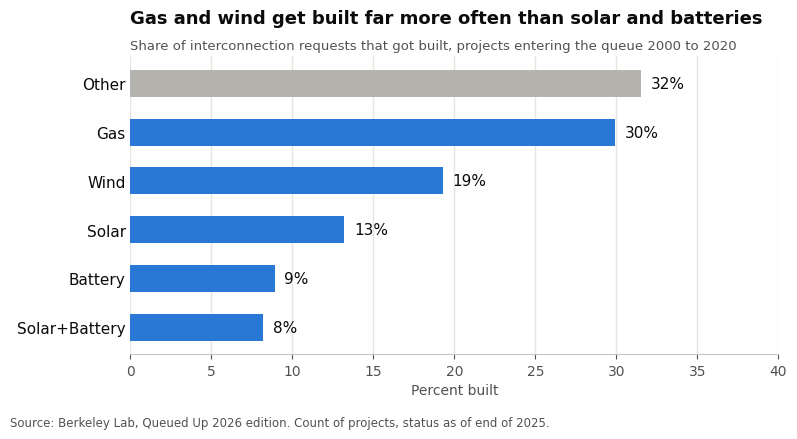

In [31]:
import matplotlib.pyplot as plt

chart = q1.sort_values('Built')
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#b4b3ad' if t == 'Other' else '#2a78d6' for t in chart.index]
bars = ax.barh(chart.index, chart['Built'], height=0.55, color=colors)

for bar, value in zip(bars, chart['Built']):
    ax.text(value + 0.6, bar.get_y() + bar.get_height() / 2, f'{value:.0f}%',
            va='center', fontsize=11, color='#0b0b0b')

ax.set_title('Gas and wind get built far more often than solar and batteries',
             loc='left', fontsize=13, fontweight='bold', color='#0b0b0b', pad=24)
ax.text(0, 1.025, 'Share of interconnection requests that got built, projects entering the queue 2000 to 2020',
        transform=ax.transAxes, fontsize=9.5, color='#52514e')
ax.set_xlabel('Percent built', color='#52514e')
ax.set_xlim(0, 40)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#c9c8c3')
ax.tick_params(axis='y', length=0, labelsize=11, colors='#0b0b0b')
ax.tick_params(axis='x', colors='#52514e')
ax.xaxis.grid(True, color='#e6e5e1', linewidth=1)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, 'Source: Berkeley Lab, Queued Up 2026 edition. Count of projects, status as of end of 2025.',
         fontsize=8.5, color='#52514e')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.savefig('/content/drive/MyDrive/Grid Line/q1_built_by_type.png', dpi=200)
plt.show()

In [32]:
built = df[df['wait_years'].notna()].copy()
built['on_year'] = built['on_date'].dt.year
print('Built projects with a wait time:', len(built))
print('Median wait overall:', round(built['wait_years'].median(), 1), 'years')
print()

by_year = built.groupby('on_year')['wait_years'].agg(
    median='median',
    low=lambda s: s.quantile(0.25),
    high=lambda s: s.quantile(0.75),
    projects='count',
).round(1)
by_year = by_year[by_year['projects'] >= 30]
print(by_year)
print()
print(built.groupby('type_group')['wait_years'].agg(['median', 'count']).round(1).sort_values('median'))

Built projects with a wait time: 3090
Median wait overall: 3.6 years

         median  low  high  projects
on_year                             
2002        2.3  1.2   3.2        38
2003        2.0  0.9   2.9        51
2004        2.4  1.4   3.7        49
2005        1.5  0.8   3.5        64
2006        1.9  1.2   3.5        77
2007        2.1  1.1   3.4        98
2008        1.8  0.8   2.9       117
2009        2.6  1.6   3.9        96
2010        2.8  2.4   4.1       107
2011        2.9  1.6   4.2       119
2012        2.6  1.7   4.8       137
2013        2.7  1.7   5.0        99
2014        3.9  2.0   5.4       105
2015        3.2  2.0   5.2       158
2016        3.5  2.0   5.7       171
2017        3.3  2.1   5.0       132
2018        3.6  2.2   5.2       142
2019        3.9  2.5   5.1       145
2020        3.7  2.6   4.6       188
2021        4.2  2.7   5.1       183
2022        4.8  3.4   6.1       156
2023        4.7  3.7   6.2       203
2024        5.1  3.7   6.6       256
2025 

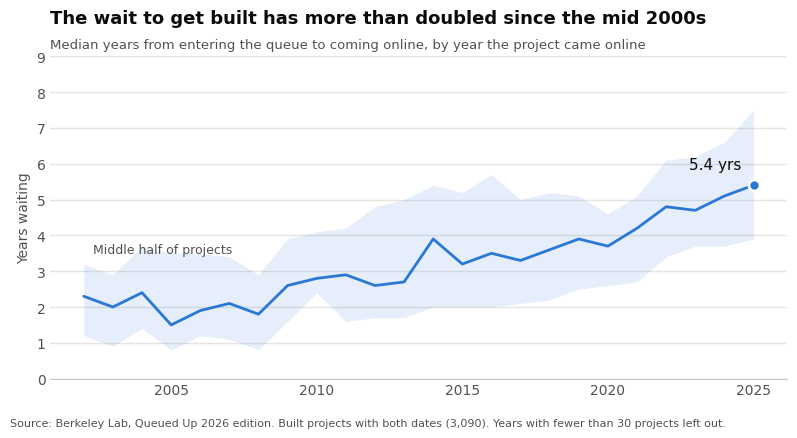

In [33]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(by_year.index, by_year['low'], by_year['high'], color='#2a78d6', alpha=0.12, linewidth=0)
ax.plot(by_year.index, by_year['median'], color='#2a78d6', linewidth=2, solid_capstyle='round')

last_year = by_year.index[-1]
last = by_year['median'].iloc[-1]
ax.plot(last_year, last, 'o', color='#2a78d6', markersize=8, markeredgecolor='white', markeredgewidth=2)
ax.text(last_year - 0.4, last + 0.45, f'{last:.1f} yrs', ha='right', fontsize=11, color='#0b0b0b')
ax.text(by_year.index[0] + 0.3, by_year['high'].iloc[0] + 0.3, 'Middle half of projects',
        fontsize=9, color='#52514e')

ax.set_title('The wait to get built has more than doubled since the mid 2000s',
             loc='left', fontsize=13, fontweight='bold', color='#0b0b0b', pad=24)
ax.text(0, 1.025, 'Median years from entering the queue to coming online, by year the project came online',
        transform=ax.transAxes, fontsize=9.5, color='#52514e')
ax.set_ylabel('Years waiting', color='#52514e')
ax.set_ylim(0, 9)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#c9c8c3')
ax.tick_params(axis='both', length=0, colors='#52514e')
ax.yaxis.grid(True, color='#e6e5e1', linewidth=1)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, 'Source: Berkeley Lab, Queued Up 2026 edition. Built projects with both dates (3,090). Years with fewer than 30 projects left out.',
         fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.savefig('/content/drive/MyDrive/Grid Line/q2_wait_by_year.png', dpi=200)
plt.show()

In [34]:
done_window = df[df['q_year'].between(2000, 2020)]

def built_share(group):
    return round((group['status'] == 'Built').mean() * 100, 1)

is_built = done_window['status'] == 'Built'
q3 = (is_built.groupby(done_window['region']).mean() * 100).round(1).rename('pct_built').to_frame()
q3['projects'] = done_window['region'].value_counts()
q3.loc['North Carolina'] = [built_share(done_window[done_window['state'] == 'NC']),
                            (done_window['state'] == 'NC').sum()]
q3.loc['All U.S.'] = [built_share(done_window), len(done_window)]
q3['projects'] = q3['projects'].astype(int)
print(q3.sort_values('pct_built'))
print()

waits = df[df['wait_years'].notna()]
wait_table = waits.groupby('region')['wait_years'].agg(['median', 'count']).round(1)
wait_table.loc['North Carolina'] = [round(waits.loc[waits['state'] == 'NC', 'wait_years'].median(), 1),
                                    (waits['state'] == 'NC').sum()]
wait_table.loc['All U.S.'] = [round(waits['wait_years'].median(), 1), len(waits)]
wait_table['count'] = wait_table['count'].astype(int)
print(wait_table.sort_values('median'))
print()

waiting = df[df['status'] == 'Still in queue']
waiting_mix = pd.crosstab(waiting['region'], waiting['type_group'], normalize='index').mul(100).round(0)
print(waiting_mix)

                pct_built  projects
region                             
NYISO                11.1       938
CAISO                12.2      1909
Southeast            15.8      2057
SPP                  16.5      1678
North Carolina       16.8       285
West                 16.9      4869
MISO                 18.2      2798
All U.S.             18.4     22159
PJM                  20.6      5536
ISO-NE               26.8       825
ERCOT                29.6      1549

                median  count
region                       
West               2.0    176
MISO               3.0    475
PJM                3.2   1179
All U.S.           3.6   3090
ERCOT              3.7    470
Southeast          3.8    215
North Carolina     4.0     48
SPP                4.1    268
NYISO              4.6     82
CAISO              6.0    225

type_group  Battery   Gas  Other  Solar  Solar+Battery  Wind
region                                                      
CAISO          40.0   0.0    7.0    6.0         

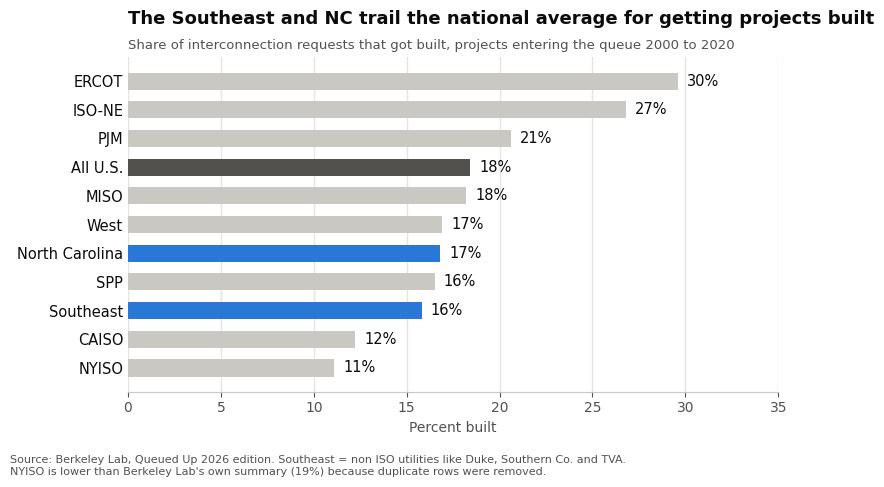

In [35]:
import matplotlib.pyplot as plt

chart = q3.sort_values('pct_built')
highlight = ['Southeast', 'North Carolina']
colors = ['#2a78d6' if r in highlight else ('#52514e' if r == 'All U.S.' else '#c9c8c3') for r in chart.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(chart.index, chart['pct_built'], height=0.6, color=colors)
for bar, value in zip(bars, chart['pct_built']):
    ax.text(value + 0.5, bar.get_y() + bar.get_height() / 2, f'{value:.0f}%',
            va='center', fontsize=10.5, color='#0b0b0b')

ax.set_title('The Southeast and NC trail the national average for getting projects built',
             loc='left', fontsize=13, fontweight='bold', color='#0b0b0b', pad=24)
ax.text(0, 1.025, 'Share of interconnection requests that got built, projects entering the queue 2000 to 2020',
        transform=ax.transAxes, fontsize=9.5, color='#52514e')
ax.set_xlabel('Percent built', color='#52514e')
ax.set_xlim(0, 35)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#c9c8c3')
ax.tick_params(axis='y', length=0, labelsize=10.5, colors='#0b0b0b')
ax.tick_params(axis='x', colors='#52514e')
ax.xaxis.grid(True, color='#e6e5e1', linewidth=1)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, 'Source: Berkeley Lab, Queued Up 2026 edition. Southeast = non ISO utilities like Duke, Southern Co. and TVA.\n'
         'NYISO is lower than Berkeley Lab\'s own summary (19%) because duplicate rows were removed.',
         fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.savefig('/content/drive/MyDrive/Grid Line/q3_built_by_region.png', dpi=200)
plt.show()